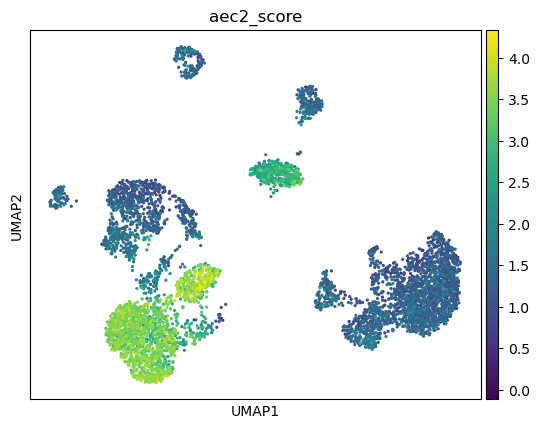

In [8]:
#healthy

import scanpy as sc
import pandas as pd
import numpy as np

# Step 1: Load the data
adata = sc.read_10x_mtx(
    r'C:\Users\Liyua\Downloads\healthy',  # <-- update path if needed
    var_names='gene_symbols',
    cache=True
)

# Step 2: Basic filtering and preprocessing
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Step 3: AEC2 marker genes
aec2_markers = ['SFTPC', 'SFTPB', 'SFTPA1', 'NAPSA', 'LAMP3']
available_markers = [gene for gene in aec2_markers if gene in adata.var_names]

# Step 4: Score cells based on AEC2 signature
sc.tl.score_genes(adata, gene_list=available_markers, score_name='aec2_score')

 #Optional: visualize the score
sc.pp.pca(adata)
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)
sc.tl.umap(adata)
sc.pl.umap(adata, color='aec2_score')

# Step 5: Select AEC2 cells based on threshold (adjustable)
aec2_cells = adata[adata.obs['aec2_score'] > 0.5]  # you can adjust this threshold as needed

# Step 6: Find top 100 genes by mean expression
mean_exp = np.asarray(aec2_cells.X.mean(axis=0)).ravel()
top_gene_indices = np.argsort(mean_exp)[::-1][:100]
top_genes = aec2_cells.var_names[top_gene_indices]

# Step 7: Save top 100 genes to CSV
pd.DataFrame(top_genes).to_csv("top100_AEC2_genes_healthy.csv", index=False, header=False)


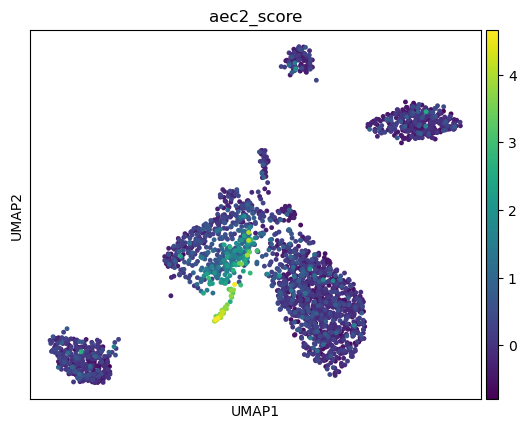

In [14]:
#IPF patient

import scanpy as sc
import pandas as pd
import numpy as np

# Step 1: Load the data
adata = sc.read_10x_mtx(
    r'C:\Users\Liyua\Downloads\GSE150068_RAW\GSM4522991_IPF33',  # <-- update path if needed
    var_names='gene_symbols',
    cache=True
)

# Step 2: Basic filtering and preprocessing
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Step 3: AEC2 marker genes
aec2_markers = ['SFTPC', 'SFTPB', 'SFTPA1', 'NAPSA', 'LAMP3']
available_markers = [gene for gene in aec2_markers if gene in adata.var_names]

# Step 4: Score cells based on AEC2 signature
sc.tl.score_genes(adata, gene_list=available_markers, score_name='aec2_score')

 #Optional: visualize the score
sc.pp.pca(adata)
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)
sc.tl.umap(adata)
sc.pl.umap(adata, color='aec2_score')

# Step 5: Select AEC2 cells based on threshold (adjustable)
aec2_cells = adata[adata.obs['aec2_score'] > 0.5]  # you can adjust this threshold as needed

# Step 6: Find top 100 genes by mean expression
mean_exp = np.asarray(aec2_cells.X.mean(axis=0)).ravel()
top_gene_indices = np.argsort(mean_exp)[::-1][:100]
top_genes = aec2_cells.var_names[top_gene_indices]

# Step 7: Save top 100 genes to CSV
pd.DataFrame(top_genes).to_csv("top100_AEC2_genes_IPF.csv", index=False, header=False)



C:\Users\Liyua\AppData\Local\Temp\ipykernel_12352\3428539745.py:45: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  combined = aec2_healthy.concatenate(aec2_ipf33, batch_key='condition', batch_categories=['healthy', 'ipf33'])


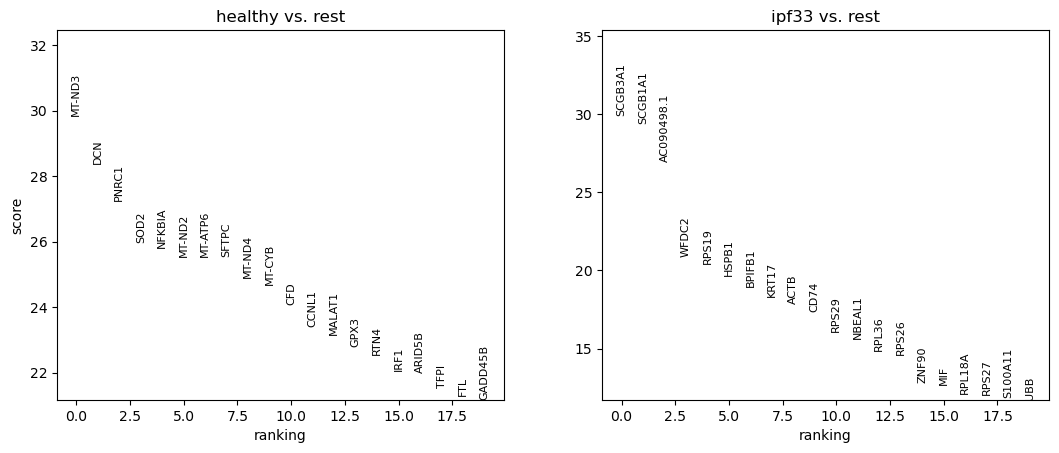

In [16]:
import scanpy as sc
import pandas as pd
import numpy as np

### ---- STEP 1: Load Healthy Dataset ---- ###
healthy_adata = sc.read_10x_mtx(
    r'C:\Users\Liyua\Downloads\healthy',
    var_names='gene_symbols',
    cache=True
)

### ---- STEP 2: Load New IPF33 Dataset ---- ###
ipf33_adata = sc.read_10x_mtx(
    r'C:\Users\Liyua\Downloads\GSE150068_RAW\GSM4522991_IPF33',
    var_names='gene_symbols',
    cache=True
)

### ---- STEP 3: Preprocess Function ---- ###
def preprocess(adata):
    sc.pp.filter_cells(adata, min_genes=200)
    sc.pp.filter_genes(adata, min_cells=3)
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    return adata

healthy_adata = preprocess(healthy_adata)
ipf33_adata = preprocess(ipf33_adata)

### ---- STEP 4: Score AEC2 Markers ---- ###
aec2_markers = ['SFTPC', 'SFTPB', 'SFTPA1', 'NAPSA', 'LAMP3']
common_markers = [g for g in aec2_markers if g in healthy_adata.var_names and g in ipf33_adata.var_names]

sc.tl.score_genes(healthy_adata, gene_list=common_markers, score_name='aec2_score')
sc.tl.score_genes(ipf33_adata, gene_list=common_markers, score_name='aec2_score')

### ---- STEP 5: Filter AEC2 Cells ---- ###
aec2_healthy = healthy_adata[healthy_adata.obs['aec2_score'] > 0.5].copy()
aec2_ipf33 = ipf33_adata[ipf33_adata.obs['aec2_score'] > 0.5].copy()

aec2_healthy.obs['condition'] = 'healthy'
aec2_ipf33.obs['condition'] = 'ipf33'

### ---- STEP 6: Combine & DEG ---- ###
combined = aec2_healthy.concatenate(aec2_ipf33, batch_key='condition', batch_categories=['healthy', 'ipf33'])

sc.tl.rank_genes_groups(combined, groupby='condition', method='wilcoxon')

# Save results
deg_df = sc.get.rank_genes_groups_df(combined, group='ipf33')
deg_df.to_csv("DEG_AEC2_IPF33_vs_Healthy.csv", index=False)

# Optional: plot
sc.pl.rank_genes_groups(combined, n_genes=20, sharey=False)


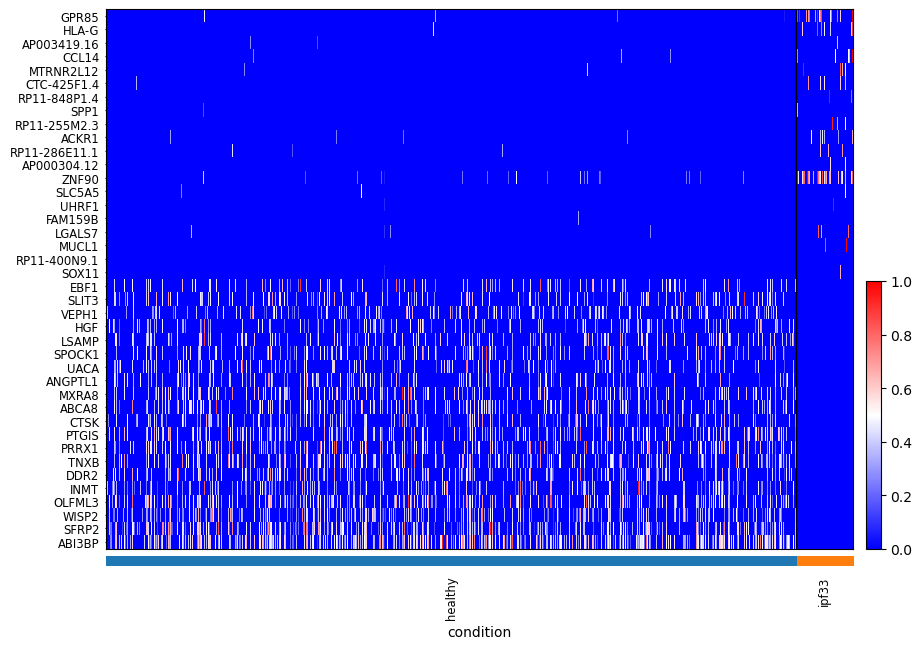

In [18]:
import scanpy as sc
import pandas as pd

# Step 1: Get full DEG results
deg_df = sc.get.rank_genes_groups_df(combined, group='ipf33')

# Step 2: Select top 20 upregulated and top 20 downregulated genes
deg_df = deg_df.sort_values('logfoldchanges', ascending=False)
top_up = deg_df['names'].head(20).tolist()
top_down = deg_df['names'].tail(20).tolist()
top_genes = top_up + top_down

# Step 3: Plot heatmap
sc.pl.heatmap(
    combined,
    var_names=top_genes,
    groupby='condition',
    swap_axes=True,
    cmap='bwr',  # blue-white-red to show up/down clearly
    show_gene_labels=True,
    dendrogram=False,
    standard_scale='var'  # normalize genes across cells
)


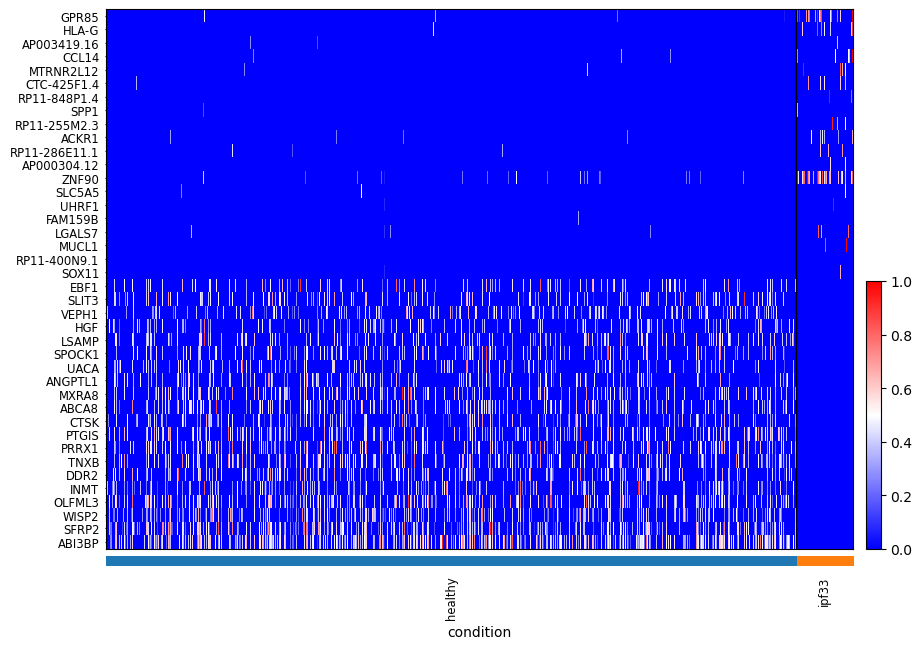

In [19]:
import scanpy as sc
import pandas as pd

# Step 1: Get full DEG results
deg_df = sc.get.rank_genes_groups_df(combined, group='ipf33')

# Save full DEG results
deg_df.to_csv("DEG_AEC2_IPF33_vs_Healthy.csv", index=False)

# Step 2: Select top 20 upregulated and top 20 downregulated genes
deg_df_sorted = deg_df.sort_values('logfoldchanges', ascending=False)
top_up = deg_df_sorted['names'].head(20).tolist()
top_down = deg_df_sorted['names'].tail(20).tolist()
top_genes = top_up + top_down

# Save top gene lists
pd.DataFrame({'upregulated': top_up}).to_csv("Top20_Upregulated_Genes.csv", index=False)
pd.DataFrame({'downregulated': top_down}).to_csv("Top20_Downregulated_Genes.csv", index=False)
pd.DataFrame({'heatmap_genes': top_genes}).to_csv("Top40_Heatmap_Genes.csv", index=False)

# Save combined AnnData object
combined.write("AEC2_combined_healthy_vs_ipf33.h5ad")

# Step 3: Plot heatmap
sc.pl.heatmap(
    combined,
    var_names=top_genes,
    groupby='condition',
    swap_axes=True,
    cmap='bwr',
    show_gene_labels=True,
    dendrogram=False,
    standard_scale='var'
)


In [21]:
deg_df = pd.read_csv("DEG_AEC2_IPF33_vs_Healthy.csv")

# Gene sets from the figure
up_genes_fig = {
    "ITGB3", "SEMA7A", "CTSE", "SERPINE1", "SHISA1", "MMP7", "ZNF469", "IL36G",
    "ADGRF4", "FBXO32", "INHBA", "ALDH1A3", "NCF2", "IL1A", "GLIPR1", "SPOCD1", "TNF", "NEURL3"
}
down_genes_fig = {
    "PDE7B", "NRGN", "HAGLR", "TENT5C", "KLF15", "EDNRB", "CA8", "HMGB2", "CHIAP2", "RRM2",
    "FOXP2", "LRRK2", "CHIA", "FOXP4-AS1", "PLIN5", "TTN", "NECAB1", "ALDH1A1", "PDCD6IPP1"
}

# Upregulated in IPF (logFC > 0)
up_in_ipf = set(deg_df[deg_df['logfoldchanges'] > 0]['names'])
down_in_ipf = set(deg_df[deg_df['logfoldchanges'] < 0]['names'])

# Overlap check
common_up = up_genes_fig & up_in_ipf
common_down = down_genes_fig & down_in_ipf

print("Common upregulated genes found in your data:", common_up)
print("Common downregulated genes found in your data:", common_down)


Common upregulated genes found in your data: {'ZNF469', 'ALDH1A3', 'CTSE', 'MMP7', 'SEMA7A'}
Common downregulated genes found in your data: {'EDNRB', 'NRGN', 'FOXP2', 'ALDH1A1', 'LRRK2', 'HAGLR', 'HMGB2', 'FOXP4-AS1', 'KLF15', 'CA8', 'TTN', 'NECAB1', 'PLIN5', 'PDE7B'}
